In [1]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import os
import numpy as np
from scipy import signal

from scipy.signal import savgol_filter
from scipy.signal import welch
from scipy.optimize import curve_fit
from scipy.stats import linregress
from scipy.fft import fft, fftfreq


In [2]:
#Data loading of temperature end voltages
def convert_and_clean(file_path):

    new_path = file_path.replace('.txt', '.parquet')

    if os.path.exists(new_path):
        print(f'Loading the existing compressed file: {new_path}')
        df = pd.read_parquet(new_path)
        return df

    try:
        print(f"Loading {file_path}...")
     
        df = pd.read_csv(file_path, sep='\t', header=None)
        df.columns = df.columns.astype(str) 
        
   
        print(f"Saving to {new_path}...")
        df.to_parquet(new_path, compression='snappy')

            
        return df
        
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Execution
file_temp = 'DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_temp2026-04-17_13-16.txt'
file_volt = 'DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_volt2026-04-17_13-17.txt'

df_temps = convert_and_clean(file_temp)
df_volts = convert_and_clean(file_volt)

cols_temps = [
    'date', 'unix_time', 
    'temp_1', 'temp_2', 'temp_3', 'temp_4', 
    'temp_5', 'temp_6', 'temp_7', 'temp_8'
]

cols_volts = ['date','unix_time','volts']
df_temps.columns = cols_temps
df_volts.columns = cols_volts

#conversion of the date in a usable format for plotting
df_temps['date'] = pd.to_datetime(df_temps['date'],errors='coerce')
df_volts['date'] = pd.to_datetime(df_volts['date'],errors='coerce')
df_volts['volts'] *= -1

print(df_temps.head())
print(df_volts.head())

Loading the existing compressed file: DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_temp2026-04-17_13-16.parquet
Loading the existing compressed file: DRM_calibrazione_T_noise_temp2026-04-17_13-16/DRM_calibrazione_T_noise_volt2026-04-17_13-17.parquet
                        date     unix_time  temp_1  temp_2  temp_3  temp_4  \
0 2026-04-17 13:16:51.269033  1.776425e+09  295.44  688.76   688.9  688.81   
1 2026-04-17 13:16:51.445341  1.776425e+09  295.44  688.76   688.9  688.81   
2 2026-04-17 13:16:51.545822  1.776425e+09  295.44  688.76   688.9  688.81   
3 2026-04-17 13:16:51.625451  1.776425e+09  295.44  688.76   688.9  688.81   
4 2026-04-17 13:16:51.715455  1.776425e+09  295.44  688.76   688.9  688.81   

   temp_5  temp_6  temp_7  temp_8  
0  295.76  295.86   295.3  295.51  
1  295.76  295.86   295.3  295.51  
2  295.76  295.86   295.3  295.51  
3  295.76  295.86   295.3  295.51  
4  295.76  295.86   295.3  295.51  
                        date     unix_t

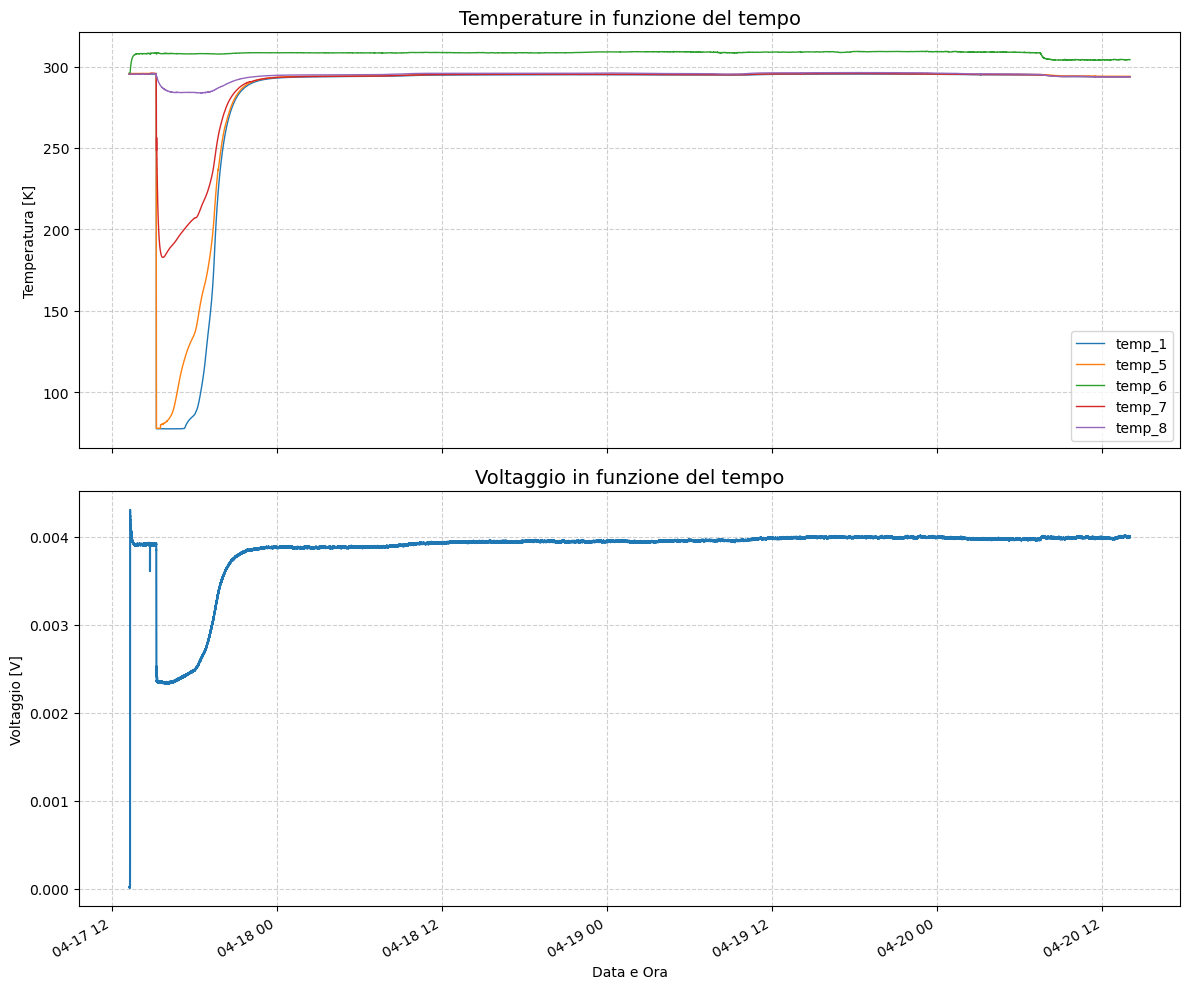

In [3]:
# Plot of the signals of temperatures and votlages
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

#Array of the functioning probes
probes= [1,5,6,7,8]

for i in probes:
    col = f'temp_{i}'
    ax1.plot(df_temps['date'], df_temps[col], label=col, linewidth=1)

ax1.set_title('Temperature in funzione del tempo', fontsize=14)
ax1.set_ylabel('Temperatura [K]')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='lower right')

ax2.plot(df_volts['date'], df_volts['volts'], label='Voltaggio', linewidth=1.5)

ax2.set_title('Voltaggio in funzione del tempo', fontsize=14)
ax2.set_xlabel('Data e Ora')
ax2.set_ylabel('Voltaggio [V]')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.gcf().autofmt_xdate()

plt.tight_layout()
plt.show()



## Noise Temperature

### DA FARE LA REGRESSIONE LINEARE CON LA MATRICE DI COVARIANZA DEI PARAMETRI PER OTTENERE L'INCERTEZZA SULLA T-NOISE

In [4]:
start_date, end_date = '2026-04-17 16:00:00', '2026-04-18 00:00:00'

volts_window = df_volts[df_volts['date'].between(start_date, end_date)].sort_values('unix_time')
temps_window = df_temps[df_temps['date'].between(start_date, end_date)].sort_values('unix_time')

# 2. Merge them based on the closest matching Unix timestamp
# This automatically resizes the data to match the length of volts_window
merged_df = pd.merge_asof(
    volts_window[['unix_time', 'volts']], 
    temps_window[['unix_time', 'temp_1']], 
    on='unix_time', 
    direction='nearest'
)

# 3. Pull out your perfectly aligned, equal-length arrays
temp_data_volts = merged_df['volts'].to_numpy()
temp_data = merged_df['temp_1'].to_numpy()
time = merged_df['unix_time']-merged_df['unix_time'][0]

print(len(temp_data))        # Will match len(volts_window)
print(len(temp_data_volts))  # Will match len(volts_window)
print(merged_df)

121992
121992
           unix_time     volts   temp_1
0       1.776434e+09  0.002345   77.410
1       1.776434e+09  0.002346   77.410
2       1.776434e+09  0.002347   77.412
3       1.776434e+09  0.002345   77.412
4       1.776434e+09  0.002346   77.413
...              ...       ...      ...
121987  1.776463e+09  0.003879  292.960
121988  1.776463e+09  0.003878  292.960
121989  1.776463e+09  0.003878  292.960
121990  1.776463e+09  0.003876  292.960
121991  1.776463e+09  0.003877  292.960

[121992 rows x 3 columns]


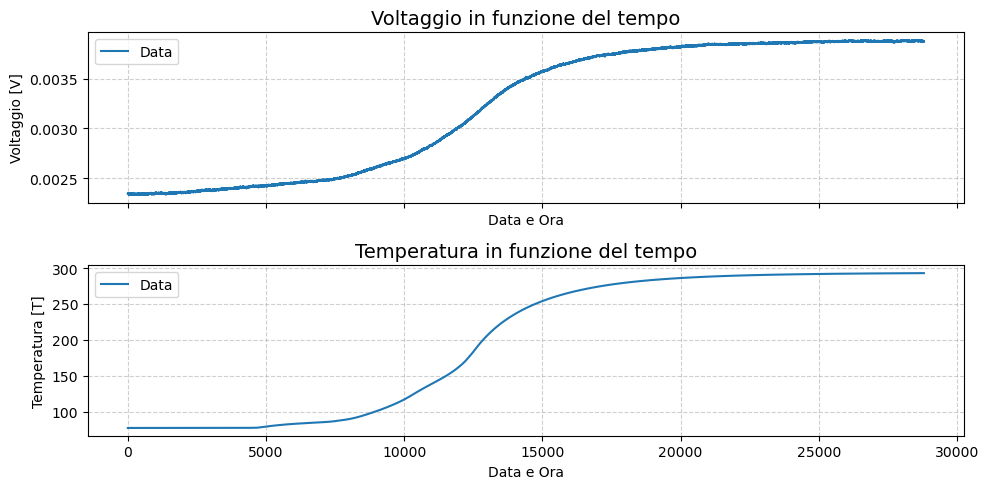

In [5]:
fig,(ax1,ax2) = plt.subplots(2,1,sharex=True, figsize=(10,5))

ax1.plot(time,temp_data_volts,label="Data")
ax1.set_title('Voltaggio in funzione del tempo', fontsize=14)
ax1.set_xlabel('Data e Ora')
ax1.set_ylabel('Voltaggio [V]')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

#probe 1 is under the feedhorn in the liquid nitrogen
ax2.plot(time,temp_data ,label="Data")
ax2.set_title('Temperatura in funzione del tempo', fontsize=14)
ax2.set_xlabel('Data e Ora')
ax2.set_ylabel('Temperatura [T]')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

fig.tight_layout()

Faccio la figura $T_v$ per trovare la $T_{noise}$  con un metodo differente


LinregressResult(slope=6.8074365475356034e-06, intercept=0.0018734343383797476, rvalue=0.9991726609774403, pvalue=0.0, stderr=7.933189899864962e-10, intercept_stderr=1.7352939926113968e-07)
T noise:275.2040838423914 +- 0.04096802690289007


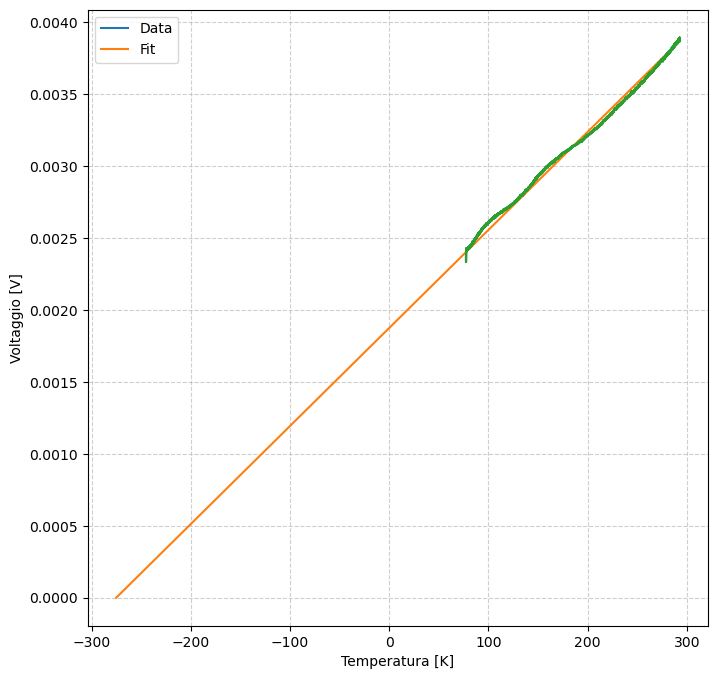

In [ ]:
reg = linregress(temp_data,temp_data_volts)
T_noise = -reg.intercept/reg.slope
T_noise_err = np.sqrt(
    (reg.intercept_stderr / reg.slope)**2 + 
    (reg.intercept * reg.stderr / (reg.slope**2))**2
)
T_teo = np.linspace(T_noise,max(temp_data),1000)

fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(temp_data,temp_data_volts,label ="Data")
ax.plot(T_teo, reg.intercept + T_teo*reg.slope, label="Fit")
ax.set_xlabel('Temperatura [K]')
ax.set_ylabel('Voltaggio [V]')
ax.grid(True, linestyle='--', alpha=0.6)

ax.legend()

plt.plot(temp_data,temp_data_volts)

#print(reg)
print(fr"T noise:{-T_noise} +- {T_noise_err}")


## Metodo alternativo mediando e trovando $T_H$ e $T_C$
Prendo come parta calda la parte di grafico prima di versa l'azoto e la parte fredda le ore in cui rimane stabile la sorgente dopo aver versato l'azoto

In [56]:
start_date_hot, end_date_hot = '2026-04-17 14:15:00', '2026-04-17 14:20:00'
start_date_cold, end_date_cold = '2026-04-17 16:15:00', '2026-04-17 16:20:00'

volts_window_cold = df_volts[df_volts['date'].between(start_date_cold, end_date_cold)].sort_values('unix_time')
temps_window_cold = df_temps[df_temps['date'].between(start_date_cold, end_date_cold)].sort_values('unix_time')

time_volts_cold = volts_window_cold['date'].to_numpy()
volts_cold = volts_window_cold['volts'].to_numpy()
time_temps_cold = temps_window_cold['date'].to_numpy()
temps_cold = temps_window_cold['temp_1'].to_numpy()


volts_window_hot = df_volts[df_volts['date'].between(start_date_hot, end_date_hot)].sort_values('unix_time')
temps_window_hot = df_temps[df_temps['date'].between(start_date_hot, end_date_hot)].sort_values('unix_time')

time_volts_hot = volts_window_hot['date'].to_numpy()
volts_hot = volts_window_hot['volts'].to_numpy()
time_temps_hot = temps_window_hot['date'].to_numpy()
temps_hot = temps_window_hot['temp_1'].to_numpy()

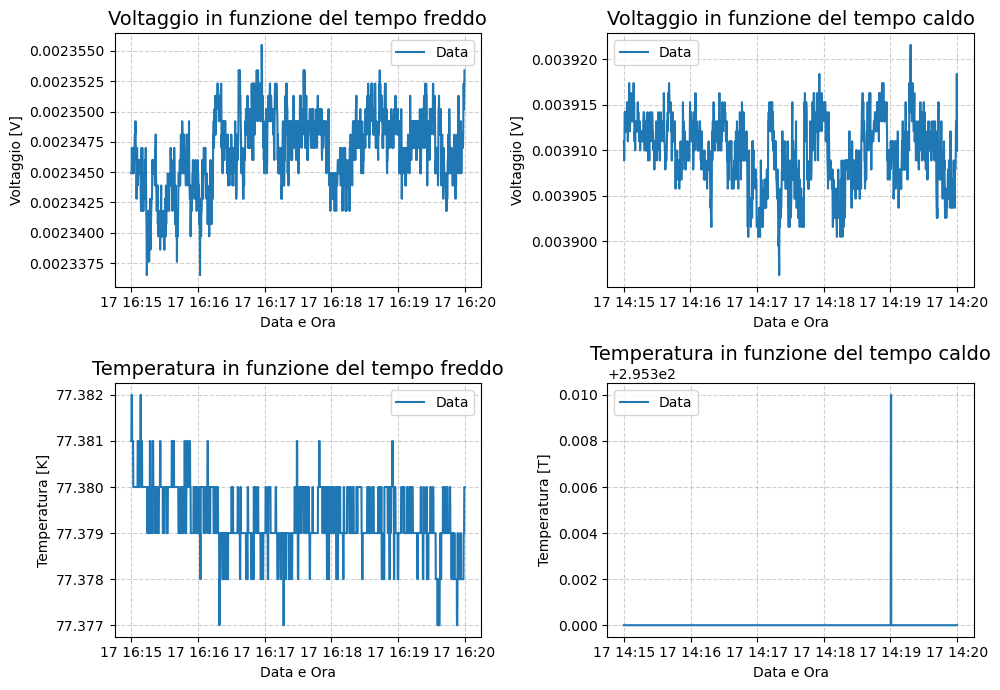

In [57]:
fig,((ax1,ax2),(ax3,ax4)) = plt.subplots(2,2, figsize=(10,7))

ax1.plot(time_volts_cold,volts_cold,label="Data")
ax1.set_title('Voltaggio in funzione del tempo freddo', fontsize=14)
ax1.set_xlabel('Data e Ora')
ax1.set_ylabel('Voltaggio [V]')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

#probe 1 is under the feedhorn in the liquid nitrogen
ax2.plot(time_volts_hot,volts_hot ,label="Data")
ax2.set_title('Voltaggio in funzione del tempo caldo', fontsize=14)
ax2.set_xlabel('Data e Ora')
ax2.set_ylabel('Voltaggio [V]')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

ax3.plot(time_temps_cold,temps_cold,label="Data")
ax3.set_title('Temperatura in funzione del tempo freddo', fontsize=14)
ax3.set_xlabel('Data e Ora')
ax3.set_ylabel('Temperatura [K]')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend()

#probe 1 is under the feedhorn in the liquid nitrogen
ax4.plot(time_temps_hot,temps_hot ,label="Data")
ax4.set_title('Temperatura in funzione del tempo caldo', fontsize=14)
ax4.set_xlabel('Data e Ora')
ax4.set_ylabel('Temperatura [T]')
ax4.grid(True, linestyle='--', alpha=0.6)
ax4.legend()

fig.tight_layout()

In [59]:
# excctracting T_hot T_cold and the uncerteinties

T_hot = np.mean(temps_hot)
T_hot_sigma = np.std(temps_hot)

T_cold = np.mean(temps_cold)
T_cold_sigma = np.std(temps_cold)

print(f"T_hot {T_hot} +- {T_hot_sigma}")
print(f"T_cold {T_cold} +- {T_cold_sigma}")


V_hot = np.mean(volts_hot)
V_hot_sigma = np.std(volts_hot)

V_cold = np.mean(volts_cold)
V_cold_sigma = np.std(volts_cold)

print(f"V_hoV {V_hot} +- {V_hot_sigma}")
print(f"V_cold {V_cold} +- {V_cold_sigma}")

Y = V_hot/V_cold
Y_sigma = np.sqrt((V_hot_sigma/V_cold)**2+(V_hot*V_cold_sigma/V_cold**2)**2)
print(f"Y {Y} +- {Y_sigma}")

T_noise = (T_hot - Y * T_cold) / (Y - 1)

# Corrected T_noise uncertainty
T_noise_sigma = np.sqrt(
    (T_hot_sigma / (Y - 1))**2 +
    (Y * T_cold_sigma / (Y - 1))**2 +
    ((T_cold - T_hot) * Y_sigma / (Y - 1)**2)**2
)


print(f"T_noise {T_noise} +- {T_noise_sigma}")

T_hot 295.3000134725498 +- 0.0003668023816786689
T_cold 77.37928575822825 +- 0.0007571113907068322
V_hoV 0.003909749567269866 +- 3.7340310145502087e-06
V_cold 0.002346828088119591 +- 3.0383371645550115e-06
Y 1.665971865200648 +- 0.0026802318979081753
T_noise 249.842837429611 +- 1.3169207316499656


## Noise measure

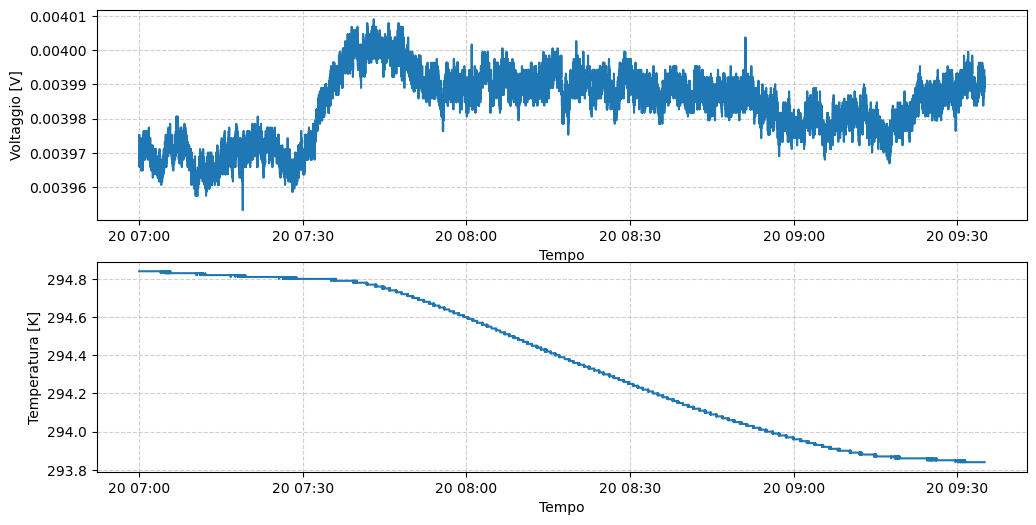

In [10]:
#mask the data to esclude the initial transient
start_date,end_date = ('2026-04-20 07:00:00', '2026-04-20 9:35:00')


mask_volts = (df_volts['date'].between(start_date,end_date)) 
volts = df_volts['volts'][mask_volts]

mask_temps = (df_temps['date'].between(start_date,end_date)) 
temps = df_temps['temp_1'][mask_temps]

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(12, 6))

ax1.plot(df_volts['date'][mask_volts],volts)
ax1.set_xlabel('Tempo')
ax1.set_ylabel('Voltaggio [V]')
ax1.grid(True, linestyle='--', alpha=0.6)


ax2.plot(df_temps['date'][mask_temps],temps)
ax2.set_xlabel('Tempo')
ax2.set_ylabel('Temperatura [K]')
ax2.grid(True, linestyle='--', alpha=0.6)

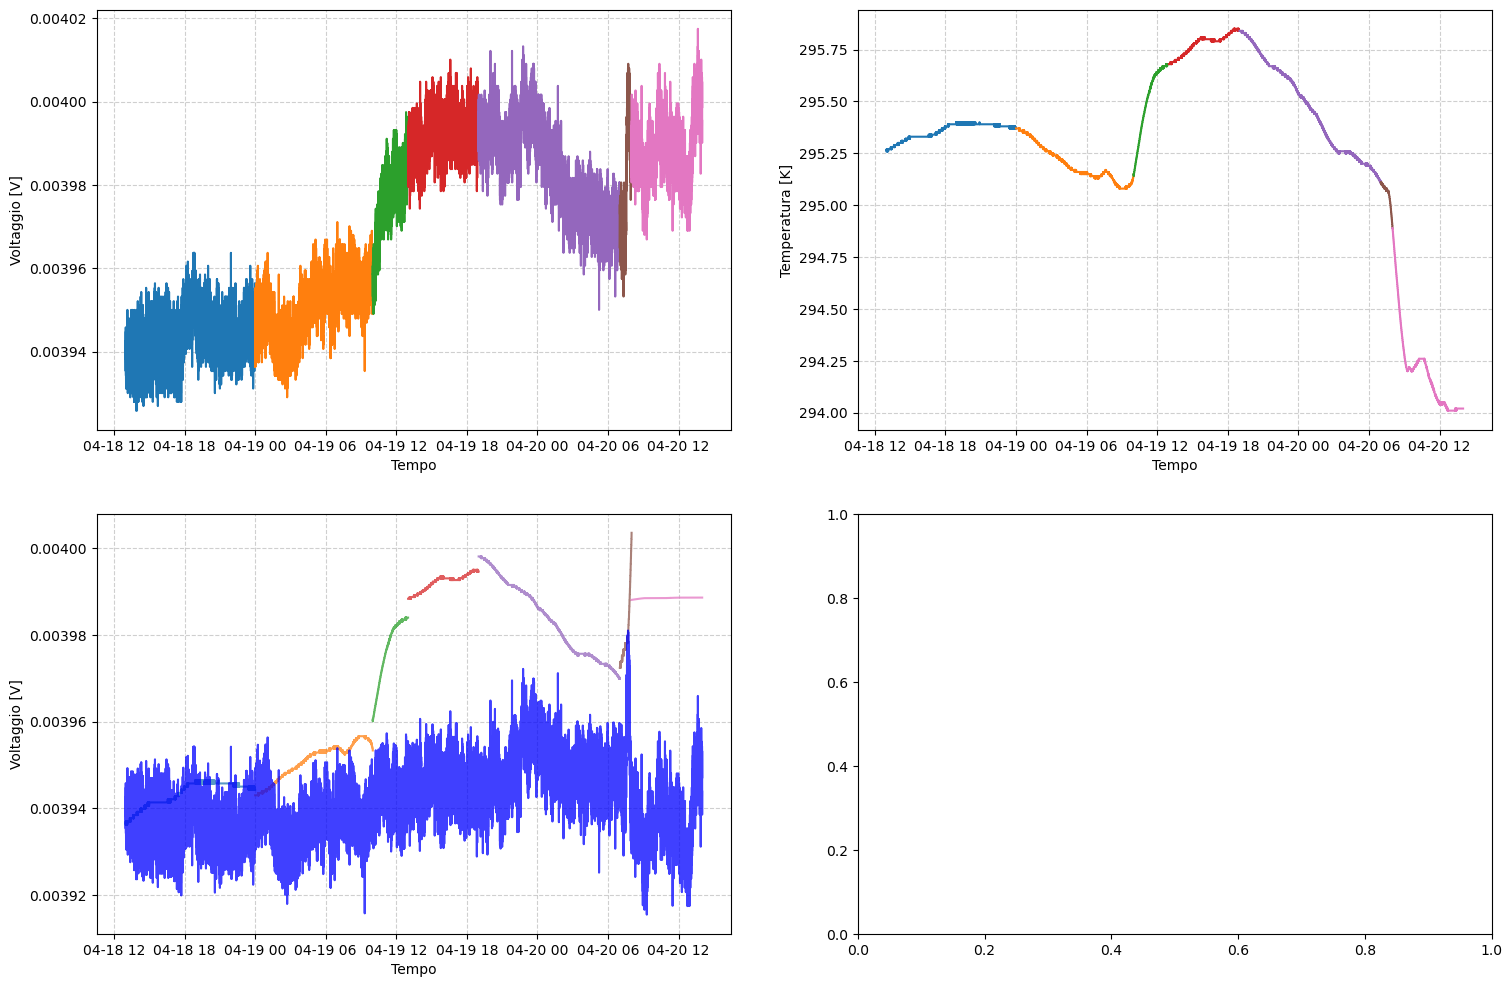

In [27]:
time_windows = [
    ('2026-04-18 13:00:00', '2026-04-19 00:00:00'),
    ('2026-04-19 00:00:00', '2026-04-19 10:00:00'),
    ('2026-04-19 10:00:00', '2026-04-19 13:00:00'),
    ('2026-04-19 13:00:00', '2026-04-19 19:00:00'),
    #('2026-04-19 17:00:00', '2026-04-19 19:00:00'),
    ('2026-04-19 19:00:00', '2026-04-20 07:00:00'),
    ('2026-04-20 07:00:00', '2026-04-20 8:00:00'),
    ('2026-04-20 8:00:00', '2026-04-20 14:00:00')
]

fig, ((ax1, ax2) ,(ax3,ax4)) = plt.subplots(2,2,figsize=(18, 12))
ax2.set_xlabel('Tempo')
ax2.set_ylabel('Temperatura [K]')
ax2.grid(True, linestyle='--', alpha=0.6)
ax1.set_xlabel('Tempo')
ax1.set_ylabel('Voltaggio [V]')
ax1.grid(True, linestyle='--', alpha=0.6)

corrected_volts = np.array([])

temp_probe = "temp_5" # thermo probe on internal ecosorb


for i, (start_date, end_date) in enumerate(time_windows):
    mask_volts = (df_volts['date'].between(start_date,end_date)) 
    volts = df_volts['volts'][mask_volts]

    mask_temps = (df_temps['date'].between(start_date,end_date)) 
    temps = df_temps[temp_probe][mask_temps] 


    ax1.plot(df_volts['date'][mask_volts],volts,label=str(i))
    ax2.plot(df_temps['date'][mask_temps],temps,label=str(i))


    merged_df = pd.merge_asof(
        df_volts[['date','unix_time', 'volts']][mask_volts], 
        df_temps[['date','unix_time', temp_probe]][mask_temps], 
        on='date', 
        direction='nearest'
    )


    # pull out your perfectly aligned, equal-length arrays
    volts = merged_df['volts'].to_numpy()
    temps = merged_df[temp_probe].to_numpy()
    date = merged_df['date'].to_numpy()
    
    # linear fit of the correcting for correlation between temperature and voltage
    reg = linregress(temps,volts)
    if i == 0:
        volts_detrended = volts - reg.slope * (temps-temps[0])
    else:
        #recentering the data with the previous detrendind
        volts_detrended = volts - reg.slope * (temps -temps[0])
        volts_detrended = volts_detrended - (volts_detrended[0] - corrected_volts[-1])

    ax3.plot(date,reg.slope*merged_df[temp_probe]+reg.intercept,alpha = 0.75)

    corrected_volts= np.concatenate((corrected_volts,volts_detrended),axis=0)


start_date,end_date = time_windows[0][0],time_windows[-1][-1]
mask_volts = (df_volts['date'].between(start_date,end_date)) 
ax3.plot(df_volts['date'][mask_volts],corrected_volts,alpha = 0.75 ,c = "blue")
ax3.set_xlabel('Tempo')
ax3.set_ylabel('Voltaggio [V]')
ax3.grid(True, linestyle='--', alpha=0.6)
    




In [34]:
# dt sampling rate of the multimeter
dt = 0.2 # integration time of the multimeter
fs = 1.0 / dt #window of welch algorithm


frequencies, psd = welch(volts_detrended, fs=fs,nperseg=64)

#low / high frequencies mask for fit (and exclude the 0.0 freq.)
lf_mask = (frequencies > 0.0 )&( frequencies < 0.8)

hf_mask = (frequencies > 0.5)

lf=frequencies[lf_mask]
hf=frequencies[hf_mask]

l_psd=psd[lf_mask]
h_psd=psd[hf_mask]


def f1_noise(f,a):
    return a/f

def white(f,k):
    return [k for _ in f]

a,pcov = curve_fit(f1_noise,frequencies[1:],psd[1:])
#k,pcov = curve_fit(white,hf,h_psd)


k = 300
N = int(len(volts)/k)+1
N_2 = int(N/2) 
x = np.linspace(0.0, N*dt, N, endpoint=False)
yf = np.abs(fft(volts)[::k+1])**2

# i take only the positive part of the frequency and discard the frequenci 0 Hz

xf = fftfreq(N, dt)[1:N_2]
yf = yf[1:N_2]

a_fft,pcov_fft = curve_fit(f1_noise,xf[:int(N_2/4)],yf[:int(N_2/4)] )

print(xf[:int(N_2/4)])

[0.01798561 0.03597122 0.05395683 0.07194245 0.08992806 0.10791367
 0.12589928 0.14388489 0.1618705  0.17985612 0.19784173 0.21582734
 0.23381295 0.25179856 0.26978417 0.28776978 0.3057554  0.32374101
 0.34172662 0.35971223 0.37769784 0.39568345 0.41366906 0.43165468
 0.44964029 0.4676259  0.48561151 0.50359712 0.52158273 0.53956835
 0.55755396 0.57553957 0.59352518 0.61151079]


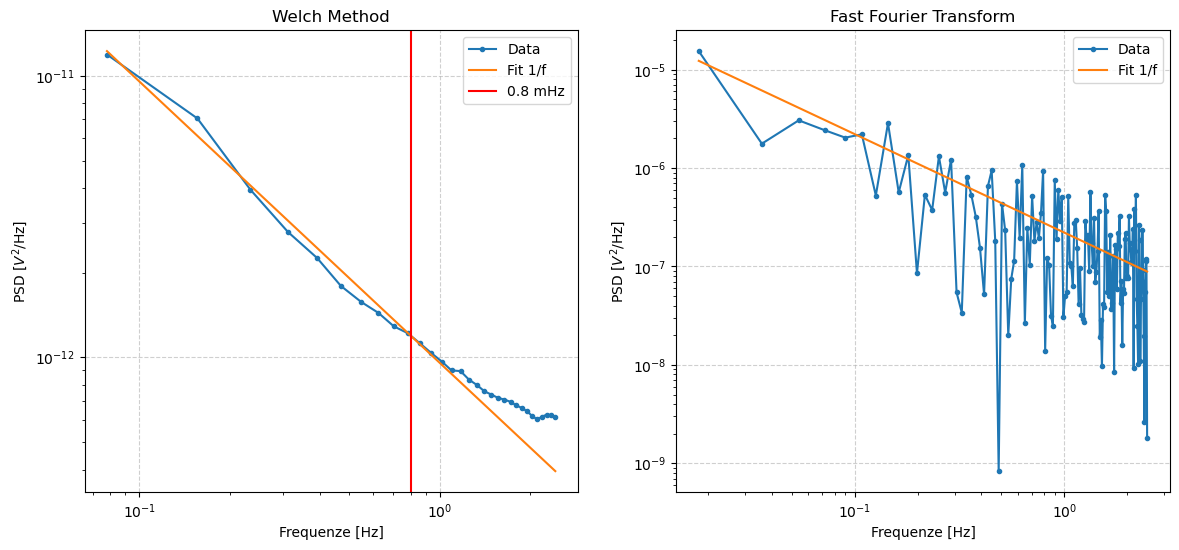

In [35]:
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(14, 6))

ax1.loglog(frequencies[1:-1],psd[1:-1],label = 'Data', marker = '.')
ax1.plot(frequencies[1:-1],f1_noise(frequencies[1:-1],a),label=r"Fit 1/f")

ax1.set_xlabel('Frequenze [Hz]')
ax1.set_ylabel(fr'PSD $[V^{2}$/Hz]')
ax1.axvline(0.8,label = "0.8 mHz",c="red")
ax1.set_title("Welch Method")
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()


ax2.loglog(xf,yf,label = 'Data',marker = '.')
ax2.plot(xf,f1_noise(xf,a_fft),label=r"Fit 1/f")
ax2.set_xlabel('Frequenze [Hz]')
ax2.set_ylabel(fr'PSD $[V^{2}$/Hz]')
ax2.set_title("Fast Fourier Transform")
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()


La frequenza di ginocchio detta dal prof dovrebbe essere 800 mHz